# Olist E-commerce Data Quality and Business Analytics

## Project Overview

This project uses the Brazilian E-Commerce Public Dataset by Olist to assess data quality and explore e-commerce sales performance with Python.

**Business objectives**
- Audit missing values, duplicate records, key uniqueness, and referential integrity.
- Analyze monthly merchandise value, delivered order volume, and average merchandise value per order.
- Identify leading product categories and measure their cumulative contribution using Pareto analysis.

**Tools:** Python, Pandas, Matplotlib, KaggleHub.

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist on Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

**Metric definition:** Merchandise value is the sum of item prices for delivered orders. It excludes freight charges and should not be interpreted as profit or accounting revenue.

**Reproducibility:** Run the notebook from top to bottom. The first code cell downloads the public dataset and loads its CSV files.

In [23]:
!pip -q install kagglehub

# Import libraries used throughout the notebook
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# Download the public Olist dataset
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Dataset directory:", path)

# Load all CSV files into a dictionary of DataFrames
csv_files = sorted(
    file for file in os.listdir(path)
    if file.lower().endswith(".csv")
)

dataframes = {
    os.path.splitext(file)[0]: pd.read_csv(os.path.join(path, file))
    for file in csv_files
}

print(f"CSV files loaded: {len(dataframes)}")
print("\nAvailable tables:")
for table_name in sorted(dataframes):
    print(f"- {table_name}")


Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Dataset directory: /kaggle/input/brazilian-ecommerce
CSV files loaded: 9

Available tables:
- olist_customers_dataset
- olist_geolocation_dataset
- olist_order_items_dataset
- olist_order_payments_dataset
- olist_order_reviews_dataset
- olist_orders_dataset
- olist_products_dataset
- olist_sellers_dataset
- product_category_name_translation


In [24]:
# Build an inventory of dataset tables
inventory = []

for table_name, df in dataframes.items():
    inventory.append({
        "table": table_name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "memory_mb": round(df.memory_usage(deep=True).sum() / (1024**2), 2)
    })

inventory_df = (
    pd.DataFrame(inventory)
    .sort_values(by="rows", ascending=False)
    .reset_index(drop=True)
)

display(inventory_df)


,table,rows,columns,memory_mb
0,olist_geolocation_dataset,1000163,5,129.38
1,olist_order_items_dataset,112650,7,35.99
2,olist_order_payments_dataset,103886,5,16.23
3,olist_customers_dataset,99441,5,26.59
4,olist_orders_dataset,99441,8,52.94
5,olist_order_reviews_dataset,99224,7,39.12
6,olist_products_dataset,32951,9,6.30
7,olist_sellers_dataset,3095,4,0.59
8,product_category_name_translation,71,2,0.01


In [25]:
# Summarize missing values and exact duplicate rows for each table
diagnostics = []

for table_name, df in dataframes.items():
    total_cells = df.size
    missing_cells = int(df.isna().sum().sum())

    diagnostics.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": missing_cells,
        "missing_cells_pct": round(
            missing_cells / total_cells * 100, 2
        ) if total_cells else 0
    })

diagnostics_df = (
    pd.DataFrame(diagnostics)
    .sort_values(by="missing_cells_pct", ascending=False)
    .reset_index(drop=True)
)

display(diagnostics_df)


,table,rows,columns,exact_duplicate_rows,missing_cells,missing_cells_pct
0,olist_order_reviews_dataset,99224,7,0,145903,21.01
1,olist_products_dataset,32951,9,0,2448,0.83
2,olist_orders_dataset,99441,8,0,4908,0.62
3,olist_customers_dataset,99441,5,0,0,0.00
4,olist_geolocation_dataset,1000163,5,261831,0,0.00
5,olist_order_payments_dataset,103886,5,0,0,0.00
6,olist_order_items_dataset,112650,7,0,0,0.00
7,olist_sellers_dataset,3095,4,0,0,0.00
8,product_category_name_translation,71,2,0,0,0.00


### 1.1. Initial Data Quality Assessment

The initial audit identified two areas for further investigation:

- **Order reviews:** 21.01% of all cells in the review table are missing. Missingness must be assessed by column because review titles and messages may be optional.
- **Geolocation:** 261,831 exact duplicate rows were detected among 1,000,163 records, representing approximately 26.18% of the table.

No records have been removed at this stage. Cleaning decisions will be based on the subsequent validation results.


In [26]:
# Inspect missing values by column in the reviews table
reviews = dataframes["olist_order_reviews_dataset"]

review_missingness = pd.DataFrame({
    "missing_values": reviews.isna().sum(),
    "missing_pct": (reviews.isna().mean() * 100).round(2),
    "data_type": reviews.dtypes.astype(str)
})

review_missingness = (
    review_missingness[review_missingness["missing_values"] > 0]
    .sort_values("missing_pct", ascending=False)
)

display(review_missingness)


,missing_values,missing_pct,data_type
review_comment_title,87656,88.34,object
review_comment_message,58247,58.70,object


In [27]:
# Inspect exact duplicates and postal-code repetition in geolocation
geo = dataframes["olist_geolocation_dataset"]

print("Total rows:", len(geo))
print("Exact duplicate rows:", int(geo.duplicated().sum()))
print(
    "Unique postal codes:",
    geo["geolocation_zip_code_prefix"].nunique()
)
print(
    "Rows repeating an existing postal code:",
    int(geo.duplicated(subset=["geolocation_zip_code_prefix"]).sum())
)

postal_code_frequency = geo["geolocation_zip_code_prefix"].value_counts()
display(postal_code_frequency.head(10))


Total rows: 1000163
Exact duplicate rows: 261831
Unique postal codes: 19015
Rows repeating an existing postal code: 981148


,count
geolocation_zip_code_prefix,
24220,1146
24230,1102
38400,965
35500,907
11680,879
22631,832
30140,810
11740,788
38408,773


### 2.1. Duplicate Removal in the Geolocation Dataset

**Objective:** Identify and remove exact duplicate records from the geolocation table while preserving valid geographic variation.

The initial assessment identified **261,831 exact duplicate rows** among 1,000,163 records, representing approximately 26.18% of the table.

**Cleaning strategy**
1. Create a working copy to preserve the original data.
2. Remove only rows that are identical across all columns.
3. Compare row counts before and after cleaning.
4. Verify that no exact duplicates remain and that the number of unique postal codes is unchanged.

**Data quality principle:** A postal code is not treated as a unique identifier for a coordinate row because one postal code may map to multiple valid geographic coordinates.

**Expected outcome:** A geolocation table with exact duplicates removed and geographic variation preserved.


In [28]:
# Create a working copy and preserve the original table
geo = dataframes["olist_geolocation_dataset"].copy()

# Record baseline metrics
rows_before = len(geo)
duplicates_before = int(geo.duplicated().sum())

# Remove only rows that are identical across every column
geo_clean = geo.drop_duplicates().copy()

# Compare before-and-after metrics
rows_after = len(geo_clean)
rows_removed = rows_before - rows_after

cleaning_summary = pd.DataFrame({
    "metric": [
        "Initial rows",
        "Exact duplicate rows identified",
        "Rows after cleaning",
        "Rows removed",
        "Reduction percentage"
    ],
    "result": [
        rows_before,
        duplicates_before,
        rows_after,
        rows_removed,
        round(rows_removed / rows_before * 100, 2)
    ]
})

display(cleaning_summary)


,metric,result
0,Initial rows,1000163.00
1,Exact duplicate rows identified,261831.00
2,Rows after cleaning,738332.00
3,Rows removed,261831.00
4,Reduction percentage,26.18


In [29]:
# Validate the cleaned geolocation table
print("Remaining exact duplicates:", int(geo_clean.duplicated().sum()))

print(
    "Unique postal codes before cleaning:",
    geo["geolocation_zip_code_prefix"].nunique()
)
print(
    "Unique postal codes after cleaning:",
    geo_clean["geolocation_zip_code_prefix"].nunique()
)

print("Missing values by column:")
display(geo_clean.isna().sum().to_frame("missing_values"))


Remaining exact duplicates: 0
Unique postal codes before cleaning: 19015
Unique postal codes after cleaning: 19015
Missing values by column:


,missing_values
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [30]:
# Check how many distinct coordinates are associated with each postal code
coordinates_by_postal_code = (
    geo_clean.groupby("geolocation_zip_code_prefix")
    .agg(
        distinct_latitudes=("geolocation_lat", "nunique"),
        distinct_longitudes=("geolocation_lng", "nunique")
    )
)

coordinates_by_postal_code["multiple_latitudes"] = (
    coordinates_by_postal_code["distinct_latitudes"] > 1
)
coordinates_by_postal_code["multiple_longitudes"] = (
    coordinates_by_postal_code["distinct_longitudes"] > 1
)

display(
    coordinates_by_postal_code.sort_values(
        "distinct_latitudes", ascending=False
    ).head(10)
)


,distinct_latitudes,distinct_longitudes,multiple_latitudes,multiple_longitudes
geolocation_zip_code_prefix,,,,
38400,746,745,True,True
11680,726,726,True,True
35500,726,726,True,True
11740,666,666,True,True
36400,627,627,True,True
39400,618,620,True,True
35162,611,611,True,True
38408,600,599,True,True
37200,595,594,True,True


### 2.2. Cleaning Results and Validation

The duplicate-removal process produced the following results:

- **Initial records:** 1,000,163
- **Exact duplicate rows removed:** 261,831
- **Records retained:** 738,332
- **Dataset size reduction:** 26.18%
- **Missing values after cleaning:** None detected
- **Unique postal codes:** 19,015 before and after cleaning

The validation confirmed that exact duplicate rows were removed and no missing values were detected in the cleaned table.

Individual postal codes can contain multiple distinct latitude and longitude values. Therefore, rows were not deduplicated by postal code.

**Conclusion:** Exact duplicate removal reduced redundancy while retaining distinct geographic records.


In [31]:
# Check uniqueness and null values in expected primary keys
primary_key_checks = {
    "orders": ("olist_orders_dataset", ["order_id"]),
    "customers": ("olist_customers_dataset", ["customer_id"]),
    "products": ("olist_products_dataset", ["product_id"]),
    "sellers": ("olist_sellers_dataset", ["seller_id"]),
}

for table_label, (table_name, key_columns) in primary_key_checks.items():
    df = dataframes[table_name]

    print(f"\n{table_label.upper()}")
    print("Key columns:", key_columns)
    print("Rows with duplicate key values:", int(df.duplicated(subset=key_columns).sum()))
    print("Rows with null key values:", int(df[key_columns].isna().any(axis=1).sum()))



ORDERS
Key columns: ['order_id']
Rows with duplicate key values: 0
Rows with null key values: 0

CUSTOMERS
Key columns: ['customer_id']
Rows with duplicate key values: 0
Rows with null key values: 0

PRODUCTS
Key columns: ['product_id']
Rows with duplicate key values: 0
Rows with null key values: 0

SELLERS
Key columns: ['seller_id']
Rows with duplicate key values: 0
Rows with null key values: 0


### 3. Referential Integrity Validation

**Objective:** Verify that foreign key values in transactional tables correspond to existing records in their respective parent tables.

Primary key validation found no duplicate or null identifiers in the `order_id`, `customer_id`, `product_id`, and `seller_id` columns of their respective tables.

The next step is to validate relationships among orders, customers, order items, products, sellers, payments, and reviews.

**Validation criteria**
1. Foreign key values should reference existing records in the parent table.
2. Missing foreign keys should be quantified and investigated.
3. Invalid references should be documented before any records are modified.

No records will be deleted during this validation stage.


In [32]:

# Define relationships between child and parent tables
relationships = [
    {
        "child": "olist_orders_dataset",
        "child_key": "customer_id",
        "parent": "olist_customers_dataset",
        "parent_key": "customer_id"
    },
    {
        "child": "olist_order_items_dataset",
        "child_key": "order_id",
        "parent": "olist_orders_dataset",
        "parent_key": "order_id"
    },
    {
        "child": "olist_order_items_dataset",
        "child_key": "product_id",
        "parent": "olist_products_dataset",
        "parent_key": "product_id"
    },
    {
        "child": "olist_order_items_dataset",
        "child_key": "seller_id",
        "parent": "olist_sellers_dataset",
        "parent_key": "seller_id"
    },
    {
        "child": "olist_order_payments_dataset",
        "child_key": "order_id",
        "parent": "olist_orders_dataset",
        "parent_key": "order_id"
    },
    {
        "child": "olist_order_reviews_dataset",
        "child_key": "order_id",
        "parent": "olist_orders_dataset",
        "parent_key": "order_id"
    }
]

results = []

for rel in relationships:
    child_df = dataframes[rel["child"]]
    parent_df = dataframes[rel["parent"]]

    foreign_key = child_df[rel["child_key"]]
    parent_keys = set(parent_df[rel["parent_key"]].dropna())

    missing = foreign_key.isna()
    orphan = foreign_key.notna() & ~foreign_key.isin(parent_keys)

    results.append({
        "child_table": rel["child"],
        "foreign_key": rel["child_key"],
        "parent_table": rel["parent"],
        "total_rows": len(child_df),
        "null_keys": int(missing.sum()),
        "orphan_keys": int(orphan.sum()),
        "orphan_percentage": round(
            orphan.sum() / len(child_df) * 100, 3
        ) if len(child_df) else 0
    })

integrity_df = pd.DataFrame(results)
display(integrity_df)


,child_table,foreign_key,parent_table,total_rows,null_keys,orphan_keys,orphan_percentage
0,olist_orders_dataset,customer_id,olist_customers_dataset,99441,0,0,0.0
1,olist_order_items_dataset,order_id,olist_orders_dataset,112650,0,0,0.0
2,olist_order_items_dataset,product_id,olist_products_dataset,112650,0,0,0.0
3,olist_order_items_dataset,seller_id,olist_sellers_dataset,112650,0,0,0.0
4,olist_order_payments_dataset,order_id,olist_orders_dataset,103886,0,0,0.0
5,olist_order_reviews_dataset,order_id,olist_orders_dataset,99224,0,0,0.0


### 3.1. Referential Integrity Validation Results

Six relationships were examined across the orders, customers, order items, products, sellers, payments, and reviews tables.

**Key findings**
- No null foreign keys were found in the six relationships examined.
- No orphan foreign keys were detected.
- All examined foreign key values matched identifiers in their corresponding parent tables.

**Conclusion:** The tested relationships passed these referential integrity checks. This supports using these keys for the subsequent joins and analysis.

No records were modified or removed during this validation stage.


## 4. Exploratory Data Analysis (EDA)

### 4.1. Monthly Sales Performance

**Business question:** How does the value of purchased merchandise evolve over time?

**Objective:** Analyze monthly merchandise value using order and order-item data to identify trends and establish a baseline for further business analysis.

**Methodology:**
1. Convert order purchase timestamps to datetime format.
2. Join order records with order-item records using `order_id`.
3. Filter for delivered orders to focus on completed deliveries.
4. Aggregate item prices by purchase month.
5. Visualize monthly merchandise value to identify trends and potential anomalies.

**Metric definition:** Merchandise value is calculated as the sum of item prices, excluding freight charges. It is not equivalent to accounting revenue or profit.

,purchase_month,merchandise_value
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


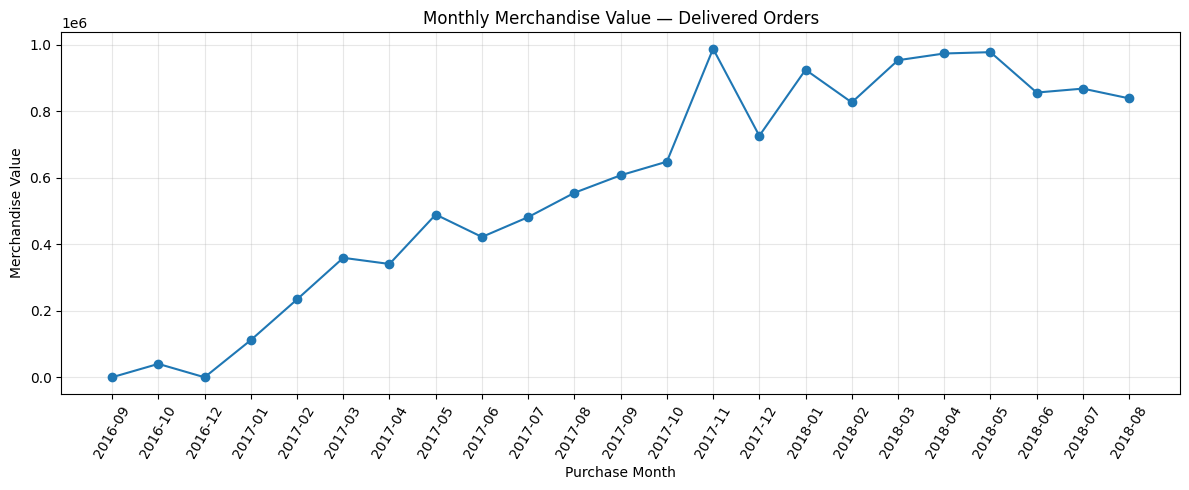

In [33]:
# Work with copies of the orders and order-items tables
orders = dataframes["olist_orders_dataset"].copy()
items = dataframes["olist_order_items_dataset"].copy()

# Convert purchase timestamps to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Keep delivered orders for this descriptive analysis
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Join delivered orders to their order items
sales = delivered_orders[
    ["order_id", "order_purchase_timestamp"]
].merge(
    items[["order_id", "price"]],
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Aggregate item prices by purchase month
sales["purchase_month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M")
)

monthly_sales = (
    sales.groupby("purchase_month")["price"]
    .sum()
    .reset_index()
)

monthly_sales["purchase_month"] = monthly_sales["purchase_month"].astype(str)
monthly_sales = monthly_sales.rename(
    columns={"price": "merchandise_value"}
)

display(monthly_sales.head(10))

# Plot monthly merchandise value
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["merchandise_value"],
    marker="o"
)
plt.title("Monthly Merchandise Value — Delivered Orders")
plt.xlabel("Purchase Month")
plt.ylabel("Merchandise Value")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4.2. Monthly Sales Trend Validation

The initial analysis suggests an upward trend in merchandise value, with notable fluctuations around November and December 2017.

Before interpreting these changes as business trends, the analysis must assess monthly data coverage, order volumes, and average merchandise value per order.

**Key questions:**
- Are all months fully represented in the dataset?
- Does the November 2017 peak reflect more orders or higher spending per order?
- Are monthly fluctuations associated with changes in order volume or average order value?

This validation will help distinguish genuine business patterns from incomplete data coverage and differences in customer purchasing behavior.

In [34]:
# Assess monthly data coverage using all orders
valid_orders = orders.dropna(subset=["order_purchase_timestamp"]).copy()
valid_orders["purchase_month"] = (
    valid_orders["order_purchase_timestamp"].dt.to_period("M")
)

coverage = (
    valid_orders.groupby("purchase_month")
    .agg(
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max"),
        total_orders=("order_id", "nunique"),
        distinct_purchase_days=("order_purchase_timestamp", "nunique")
    )
    .reset_index()
)

coverage["days_in_month"] = coverage["purchase_month"].dt.days_in_month
coverage["first_calendar_day"] = coverage["first_purchase"].dt.day
coverage["last_calendar_day"] = coverage["last_purchase"].dt.day
coverage["is_first_or_last_dataset_month"] = (
    (coverage["purchase_month"] == coverage["purchase_month"].min()) |
    (coverage["purchase_month"] == coverage["purchase_month"].max())
)

# Calculate monthly metrics using delivered orders and their item prices
monthly_metrics = (
    sales.groupby("purchase_month")
    .agg(
        merchandise_value=("price", "sum"),
        delivered_order_count=("order_id", "nunique")
    )
    .reset_index()
)

monthly_metrics["avg_merchandise_value_per_order"] = (
    monthly_metrics["merchandise_value"]
    / monthly_metrics["delivered_order_count"]
)

monthly_analysis = monthly_metrics.merge(
    coverage,
    on="purchase_month",
    how="left"
)

display(
    monthly_analysis.sort_values(
        "merchandise_value", ascending=False
    ).head(10)
)


,purchase_month,merchandise_value,delivered_order_count,avg_merchandise_value_per_order,first_purchase,last_purchase,total_orders,distinct_purchase_days,days_in_month,first_calendar_day,last_calendar_day,is_first_or_last_dataset_month
13,2017-11,987765.37,7289,135.514525,2017-11-01 00:12:34,2017-11-30 23:36:03,7544,7475,30,1,30,False
19,2018-05,977544.69,6749,144.842894,2018-05-01 00:02:11,2018-05-31 23:51:24,6873,6839,31,1,31,False
18,2018-04,973534.09,6798,143.208898,2018-04-01 00:11:32,2018-04-30 23:47:26,6939,6903,30,1,30,False
17,2018-03,953356.25,7003,136.135406,2018-03-01 00:00:00,2018-03-31 23:54:10,7211,7151,31,1,31,False
15,2018-01,924645.00,7069,130.802801,2018-01-01 02:48:41,2018-01-31 23:58:22,7269,7233,31,1,31,False
21,2018-07,867953.46,6159,140.924413,2018-07-01 00:25:07,2018-07-31 23:54:20,6292,6252,31,1,31,False
20,2018-06,856077.86,6099,140.363643,2018-06-01 00:39:55,2018-06-30 23:59:49,6167,6143,30,1,30,False
22,2018-08,838576.64,6351,132.038520,2018-08-01 00:02:17,2018-08-31 16:13:44,6512,6477,31,1,31,False
16,2018-02,826437.13,6555,126.077365,2018-02-01 00:24:55,2018-02-28 23:57:55,6728,6679,28,1,28,False
14,2017-12,726033.19,5513,131.694756,2017-12-01 00:01:14,2017-12-31 23:29:31,5673,5643,31,1,31,False


### 4.3. Initial Business Findings

November 2017 had the highest monthly merchandise value in the analyzed period, at approximately R$987,765 across 7,289 delivered orders.

May 2018 recorded approximately R$977,545 across 6,749 delivered orders. Average merchandise value per delivered order was approximately R$144.84 in May 2018, compared with R$135.51 in November 2017.

These results suggest that monthly merchandise value reflects both order volume and average merchandise value per order.

**Limitations:** The analysis includes delivered orders and attributes their item value to the purchase month. Monthly coverage and possible selection effects should be considered before drawing conclusions about business performance or seasonality.


,purchase_month,merchandise_value,delivered_order_count,avg_merchandise_value_per_order
13,2017-11,987765.37,7289,135.514525
19,2018-05,977544.69,6749,144.842894
18,2018-04,973534.09,6798,143.208898
17,2018-03,953356.25,7003,136.135406
15,2018-01,924645.00,7069,130.802801
21,2018-07,867953.46,6159,140.924413
20,2018-06,856077.86,6099,140.363643
22,2018-08,838576.64,6351,132.038520
16,2018-02,826437.13,6555,126.077365
14,2017-12,726033.19,5513,131.694756


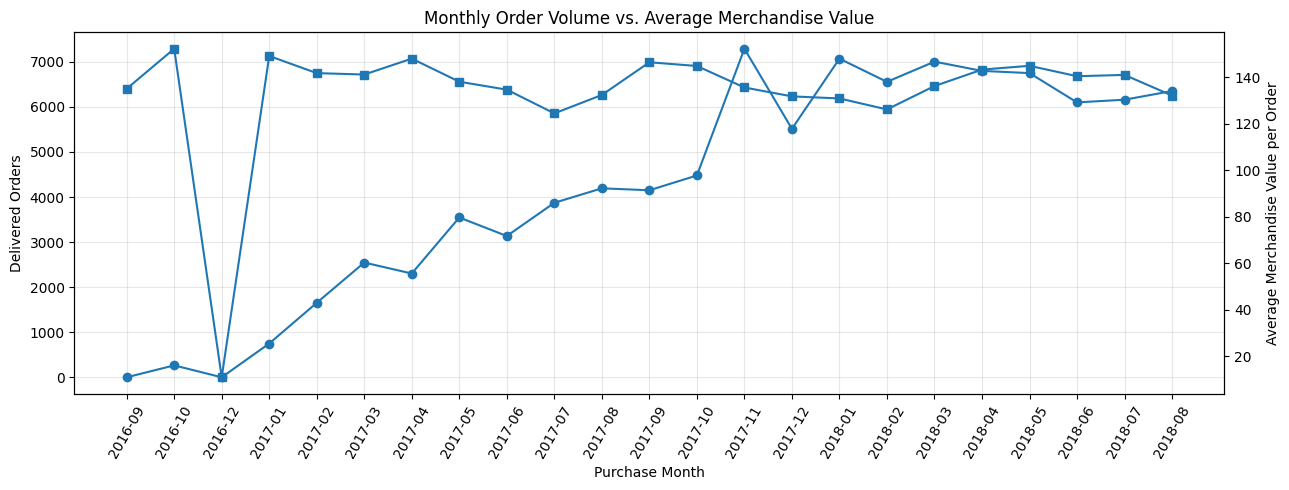

In [35]:
# Prepare a chronologically sorted monthly comparison table
monthly_comparison = monthly_metrics.copy()
monthly_comparison["purchase_month"] = (
    monthly_comparison["purchase_month"].astype(str)
)
monthly_comparison = monthly_comparison.sort_values("purchase_month")

display(
    monthly_comparison.sort_values(
        "merchandise_value", ascending=False
    ).head(10)
)

# Compare delivered order volume and average merchandise value per order
fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(
    monthly_comparison["purchase_month"],
    monthly_comparison["delivered_order_count"],
    marker="o"
)
ax1.set_xlabel("Purchase Month")
ax1.set_ylabel("Delivered Orders")
ax1.tick_params(axis="x", rotation=60)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    monthly_comparison["purchase_month"],
    monthly_comparison["avg_merchandise_value_per_order"],
    marker="s"
)
ax2.set_ylabel("Average Merchandise Value per Order")

plt.title("Monthly Order Volume vs. Average Merchandise Value")
plt.tight_layout()
plt.show()


In [36]:
# Inspect the earliest months and months with the lowest order counts
display(
    monthly_comparison[
        ["purchase_month", "merchandise_value",
         "delivered_order_count", "avg_merchandise_value_per_order"]
    ].head(8)
)

display(
    monthly_comparison.nsmallest(5, "delivered_order_count")
)


,purchase_month,merchandise_value,delivered_order_count,avg_merchandise_value_per_order
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,265,152.170226
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,750,149.064480
4,2017-02,234223.40,1653,141.695947
5,2017-03,359198.85,2546,141.083602
6,2017-04,340669.68,2303,147.924307
7,2017-05,489338.25,3546,137.997250


,purchase_month,merchandise_value,delivered_order_count,avg_merchandise_value_per_order
0,2016-09,134.97,1,134.970000
2,2016-12,10.90,1,10.900000
1,2016-10,40325.11,265,152.170226
3,2017-01,111798.36,750,149.064480
4,2017-02,234223.40,1653,141.695947


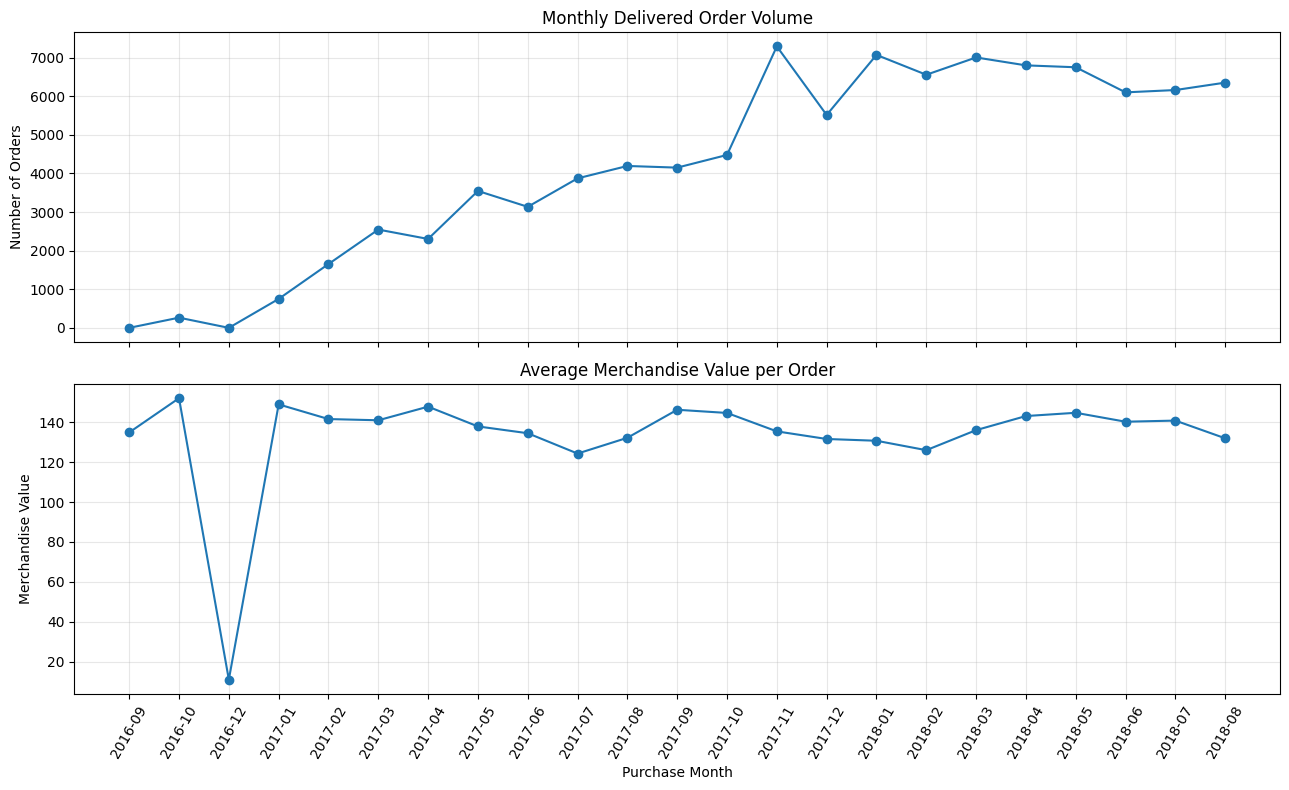

In [37]:
# Plot order volume and average merchandise value in separate panels
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(
    monthly_comparison["purchase_month"],
    monthly_comparison["delivered_order_count"],
    marker="o"
)
axes[0].set_title("Monthly Delivered Order Volume")
axes[0].set_ylabel("Number of Orders")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_comparison["purchase_month"],
    monthly_comparison["avg_merchandise_value_per_order"],
    marker="o"
)
axes[1].set_title("Average Merchandise Value per Order")
axes[1].set_ylabel("Merchandise Value")
axes[1].set_xlabel("Purchase Month")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


### 4.4. Order Volume and Average Merchandise Value

The analysis indicates that monthly merchandise value varies with delivered order volume, while average merchandise value per order is comparatively stable across most observed months.

December 2016 is an exception, with an unusually low average. Further investigation found only one delivered order in that month, with a merchandise value of R$10.90.

**Business implication:** Monitoring order volume alongside average merchandise value provides more context than analyzing total merchandise value alone.

**Limitation:** These descriptive results do not establish the causes of the observed trends. They represent delivered orders grouped by purchase month, not all purchases or recognized accounting revenue.


In [38]:
# Investigate the December 2016 delivered-order anomaly
dec_orders = sales[
    sales["purchase_month"] == pd.Period("2016-12", freq="M")
]

print("Order-item rows:", len(dec_orders))
print("Unique delivered orders:", dec_orders["order_id"].nunique())
print("Total merchandise value:", round(dec_orders["price"].sum(), 2))

display(dec_orders.sort_values("price").head(10))


Order-item rows: 1
Unique delivered orders: 1
Total merchandise value: 10.9


,order_id,order_purchase_timestamp,price,purchase_month
44038,bd50a7fe9fd97ea4b7663031a319e150,2016-12-23 23:16:47,10.9,2016-12


### 4.5. Investigation of the December 2016 Anomaly

The unusually low average merchandise value in December 2016 was investigated by examining the underlying delivered orders.

The analysis identified **one delivered order**, with a merchandise value of R$10.90. This explains the unusually low monthly average and means that the month is not representative of typical purchasing behavior in this dataset.

**Analytical decision:** December 2016 remains in the dataset to preserve the observed information, but it is flagged as a low-volume month and interpreted cautiously in month-to-month comparisons.

**Key lesson:** Aggregate metrics should be evaluated alongside their underlying sample sizes to avoid misleading business conclusions.


In [39]:
# Flag months with fewer than 100 delivered orders for further review
monthly_comparison["low_volume_month"] = (
    monthly_comparison["delivered_order_count"] < 100
)

display(
    monthly_comparison[
        ["purchase_month", "delivered_order_count",
         "avg_merchandise_value_per_order", "low_volume_month"]
    ]
)


,purchase_month,delivered_order_count,avg_merchandise_value_per_order,low_volume_month
0,2016-09,1,134.970000,True
1,2016-10,265,152.170226,False
2,2016-12,1,10.900000,True
3,2017-01,750,149.064480,False
4,2017-02,1653,141.695947,False
5,2017-03,2546,141.083602,False
6,2017-04,2303,147.924307,False
7,2017-05,3546,137.997250,False
8,2017-06,3135,134.584807,False
9,2017-07,3872,124.381333,False


## 5. Product Category Performance

### 5.1. Merchandise Value by Product Category

**Business question:** Which product categories contribute the most to total merchandise value?

**Objective:** Identify the leading product categories by merchandise value and quantify their contribution to total sales.

**Methodology:**
1. Join order items with product information.
2. Join the category translation table to obtain English category names.
3. Aggregate merchandise value and item volume by category.
4. Calculate each category's percentage contribution to total merchandise value.
5. Rank categories to identify the largest contributors.

**Metric definition:** Merchandise value is calculated as the sum of item prices for delivered orders. Freight charges are excluded, and the metric should not be interpreted as profit.

In [40]:


# Load the product and category translation tables
products = dataframes["olist_products_dataset"].copy()

category_translation = dataframes[
    "product_category_name_translation"
].copy()

# Select order IDs that were delivered
delivered_order_ids = set(
    orders.loc[
        orders["order_status"] == "delivered",
        "order_id"
    ]
)

# Filter original order items without joining on price
delivered_items = items[
    items["order_id"].isin(delivered_order_ids)
].copy()

# Attach product categories
category_sales = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Use English category names when available
category_sales["category"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"])
    .fillna("Unknown")
)

# Aggregate category metrics
category_summary = (
    category_sales.groupby("category")
    .agg(
        merchandise_value=("price", "sum"),
        items_sold=("order_item_id", "count")
    )
    .reset_index()
)

# Calculate category contribution
total_value = category_summary["merchandise_value"].sum()

category_summary["share_pct"] = (
    category_summary["merchandise_value"]
    / total_value
    * 100
)

category_summary = (
    category_summary
    .sort_values("merchandise_value", ascending=False)
    .reset_index(drop=True)
)

display(category_summary.head(15))



,category,merchandise_value,items_sold,share_pct
0,health_beauty,1233131.72,9465,9.326717
1,watches_gifts,1166176.98,5859,8.820309
2,bed_bath_table,1023434.76,10953,7.740687
3,sports_leisure,954852.55,8431,7.221969
4,computers_accessories,888724.61,7644,6.721815
5,furniture_decor,711927.69,8160,5.384622
6,housewares,615628.69,6795,4.656270
7,cool_stuff,610204.10,3718,4.615242
8,auto,578966.65,4140,4.378979
9,toys,471286.48,4030,3.564547


### 5.2. Key Findings: Product Category Performance

The category analysis identified **Health & Beauty** as the leading product category by merchandise value, generating R$1,233,131.72 and accounting for 9.33% of the total analyzed value.

**Watches & Gifts** ranked second, with R$1,166,176.98 (8.82%), followed by **Bed, Bath & Table**, with R$1,023,434.76 (7.74%).

Together, these three categories account for approximately **25.89% of total merchandise value** in the analyzed delivered orders.

**Business Implications:**
- Health & Beauty represents the largest category by merchandise value in this analysis.
- Watches & Gifts generates a high merchandise value with fewer items sold than the leading category.
- Bed, Bath & Table combines a high merchandise value with the largest item volume among the top three categories.

**Limitations:** Merchandise value does not measure profitability. The analysis does not account for product costs, marketing expenses, discounts, or category-specific margins.

**Recommendation:** Further investigate category concentration and the cumulative contribution of leading categories before making inventory or marketing allocation decisions.

In [41]:
# Rank product categories and calculate cumulative contribution
pareto = category_summary.sort_values(
    "merchandise_value",
    ascending=False
).copy()

total_value = pareto["merchandise_value"].sum()
pareto["share_pct"] = pareto["merchandise_value"] / total_value * 100
pareto["cumulative_share_pct"] = pareto["share_pct"].cumsum()
pareto["category_rank"] = range(1, len(pareto) + 1)

# Identify the number of categories needed to reach at least 80%
categories_for_80 = int((pareto["cumulative_share_pct"] < 80).sum() + 1)

print("Total categories:", len(pareto))
print("Categories needed to reach at least 80%:", categories_for_80)
print(
    "Cumulative contribution at this threshold:",
    f"{pareto.iloc[categories_for_80 - 1]['cumulative_share_pct']:.2f}%"
)

display(
    pareto[
        ["category_rank", "category", "merchandise_value",
         "share_pct", "cumulative_share_pct"]
    ].head(15)
)


Total categories: 74
Categories needed to reach at least 80%: 18
Cumulative contribution at this threshold: 81.29%


,category_rank,category,merchandise_value,share_pct,cumulative_share_pct
0,1,health_beauty,1233131.72,9.326717,9.326717
1,2,watches_gifts,1166176.98,8.820309,18.147026
2,3,bed_bath_table,1023434.76,7.740687,25.887713
3,4,sports_leisure,954852.55,7.221969,33.109682
4,5,computers_accessories,888724.61,6.721815,39.831497
5,6,furniture_decor,711927.69,5.384622,45.216119
6,7,housewares,615628.69,4.656270,49.872389
7,8,cool_stuff,610204.10,4.615242,54.487631
8,9,auto,578966.65,4.378979,58.866610
9,10,toys,471286.48,3.564547,62.431157


### 5.3. Pareto Analysis: Category Contribution

The Pareto analysis evaluated merchandise value across 74 product categories.

The results show that **18 categories are required to account for at least 80% of total merchandise value**. The top three categories contribute 25.89%, the top five contribute 39.83%, and the top ten contribute 62.43%.

**Key finding:** Merchandise value is distributed across a relatively broad set of categories rather than being concentrated exclusively in a small number of them.

**Business implications:**
- The leading categories deserve attention when prioritizing commercial analysis.
- Inventory and marketing decisions should consider both category contribution and additional metrics such as profitability, demand variability, and inventory turnover.
- Lower-ranked categories should not automatically be deprioritized, as they may serve important customer needs.

**Limitation:** This analysis measures merchandise value, not profit or inventory efficiency. The 80% threshold is an analytical benchmark rather than a universal business rule.

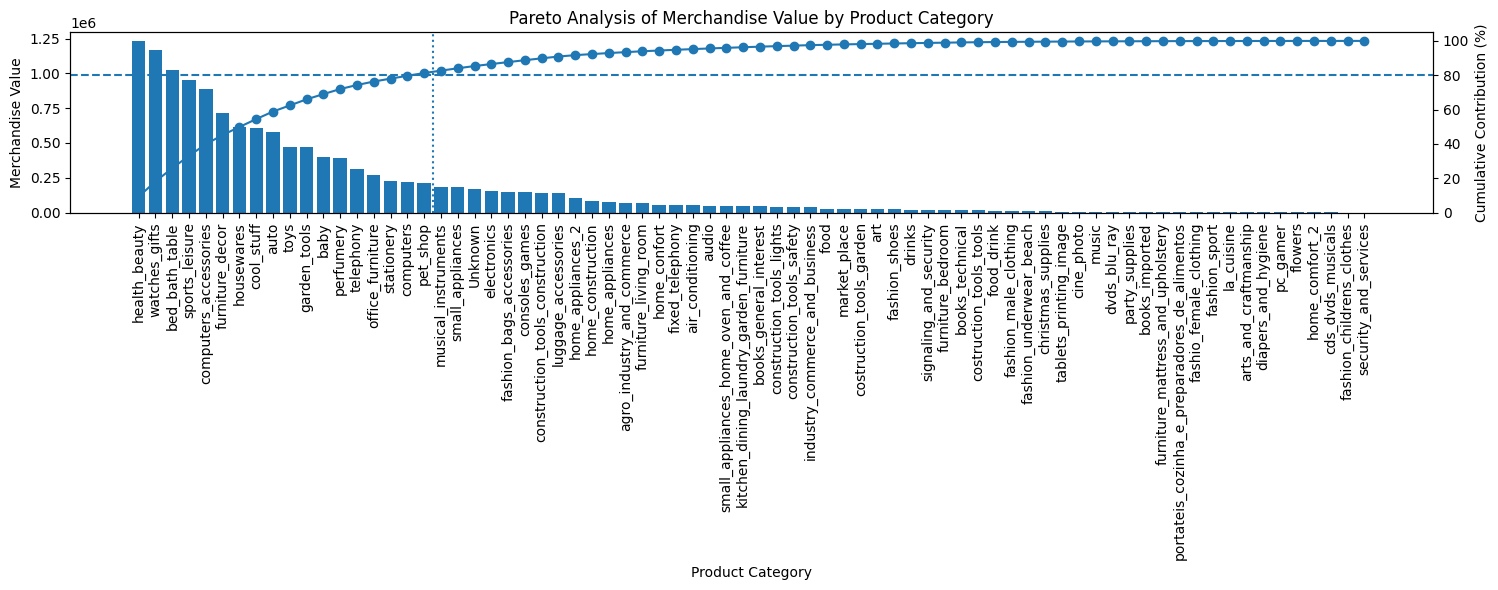

In [42]:
# Plot the full Pareto distribution across all product categories
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.bar(
    pareto["category"],
    pareto["merchandise_value"]
)
ax1.set_ylabel("Merchandise Value")
ax1.set_xlabel("Product Category")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(
    pareto["category"],
    pareto["cumulative_share_pct"],
    marker="o"
)
ax2.axhline(y=80, linestyle="--")
ax2.set_ylabel("Cumulative Contribution (%)")
ax2.set_ylim(0, 105)

ax1.axvline(
    x=categories_for_80 - 0.5,
    linestyle=":",
    label=f"80% threshold: {categories_for_80} categories"
)

plt.title("Pareto Analysis of Merchandise Value by Product Category")
fig.tight_layout()
plt.show()


### 5.4. Pareto Analysis — Results and Business Implications

The Pareto analysis covered 74 product categories. The results show that **18 categories account for at least 80% of total merchandise value**.

Health & Beauty ranks first, followed by Watches & Gifts and Bed, Bath & Table. The top five categories contribute approximately 39.83% of merchandise value, while the top ten account for approximately 62.43%.

**Business implications:**
- Prioritize the leading categories for deeper analysis of demand, pricing, and product availability.
- Evaluate the contribution of the remaining categories before making assortment or inventory decisions.
- Combine merchandise value with profitability and inventory turnover metrics to develop more effective commercial strategies.

**Conclusion:** Merchandise value is distributed across a relatively broad range of categories. The 80% threshold provides a useful prioritization benchmark, but it should not be interpreted as evidence that lower-ranked categories are unimportant.

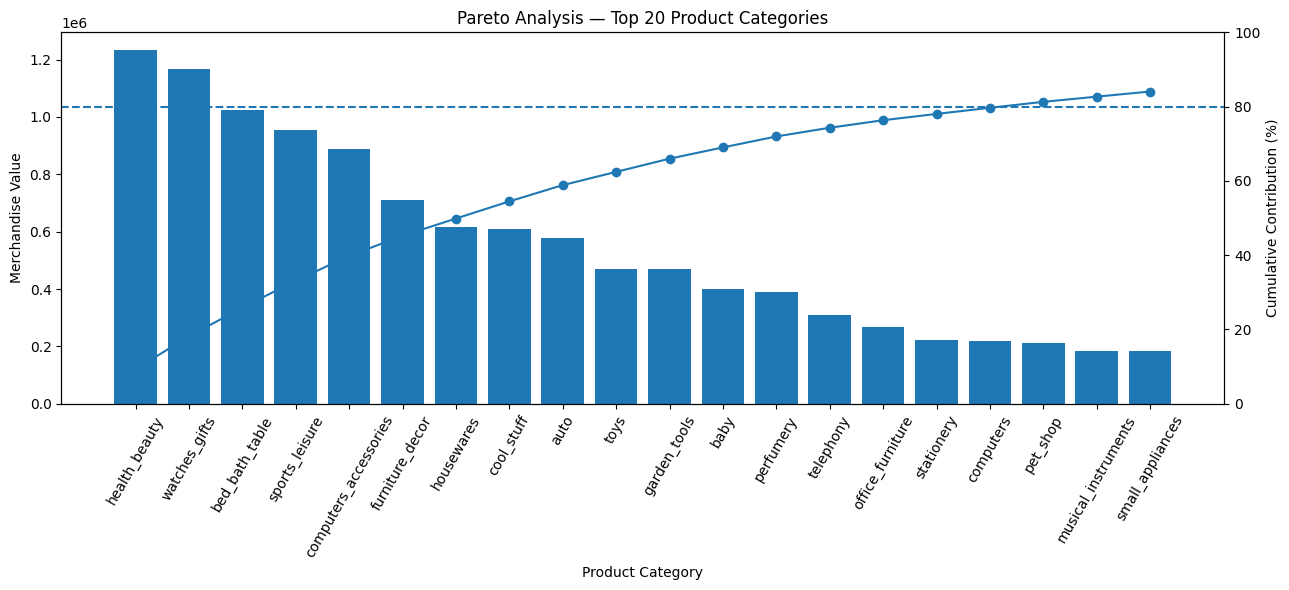

In [43]:
# Plot the 20 leading categories for a more readable presentation
top_n = 20
pareto_top = pareto.head(top_n).copy()

fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.bar(
    pareto_top["category"],
    pareto_top["merchandise_value"]
)
ax1.set_ylabel("Merchandise Value")
ax1.set_xlabel("Product Category")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(
    pareto_top["category"],
    pareto_top["cumulative_share_pct"],
    marker="o"
)
ax2.axhline(y=80, linestyle="--")
ax2.set_ylabel("Cumulative Contribution (%)")
ax2.set_ylim(0, 100)

plt.title("Pareto Analysis — Top 20 Product Categories")
fig.tight_layout()
plt.show()


## 6. Executive Summary and Next Steps

### Key findings
- The geolocation table contained 261,831 exact duplicate rows (26.18% of its initial records). Removing exact duplicates retained 738,332 rows and preserved all 19,015 unique postal codes.
- The four primary-key checks passed, and the six tested foreign-key relationships had no null or orphan keys.
- Monthly merchandise value generally increased over the observed period, alongside delivered order volume. December 2016 had only one delivered order and should be interpreted cautiously.
- Health & Beauty was the leading product category by merchandise value, followed by Watches & Gifts and Bed, Bath & Table.
- The top three categories contributed approximately 25.89% of merchandise value, and 18 of the 74 categories accounted for at least 80%.

### Business implications
The analysis establishes a baseline for monitoring merchandise value, delivered order volume, and category contribution. Decisions about marketing, inventory, or assortment should also consider profitability, costs, stock availability, and demand variability, which are not measured in this dataset analysis.

### Limitations
- The dataset is historical and does not represent current marketplace performance.
- Merchandise value is based on item prices for delivered orders; freight is excluded, and this metric is not profit or accounting revenue.
- Missing review titles and messages may be expected for optional text fields and were not imputed.
- The low-volume flag uses an exploratory threshold of fewer than 100 delivered orders per month; it is a review aid, not a universal standard.

### Recommended next steps
1. Extend the analysis with customer-level metrics and cohort behavior.
2. Build a separate customer-segmentation notebook using RFM features and K-means.
3. If business cost or margin data becomes available, complement merchandise value with profitability analysis.